In [1]:
%pip install Pillow scikit-image numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [8]:
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter
import numpy as np
import matplotlib.pyplot as plt
from skimage import color, filters
from pathlib import Path

# Función para comparar las imágenes.
def mostrar(imagenes, titulos):
    fig, ejes = plt.subplots(
        1, len(imagenes),
        figsize=(4 * len(imagenes), 4),
        squeeze=False
    )

    for eje, imagen, titulo in zip(ejes.ravel(), imagenes, titulos):
        arreglo = np.asarray(imagen)

        if arreglo.ndim == 2:
            limite = 1 if arreglo.dtype == bool or arreglo.max() <= 1 else 255
            eje.imshow(
                arreglo, cmap="gray",
                vmin=0, vmax=limite,
                interpolation="nearest"
            )
        else:
            eje.imshow(arreglo, interpolation="nearest")

        eje.set_title(titulo)
        eje.axis("off")

    plt.tight_layout()
    plt.show()

print("Los archivos se guardarán en:", Path.cwd())

Los archivos se guardarán en: C:\Users\51950


Tamaño: (120, 120)
Modo: RGB


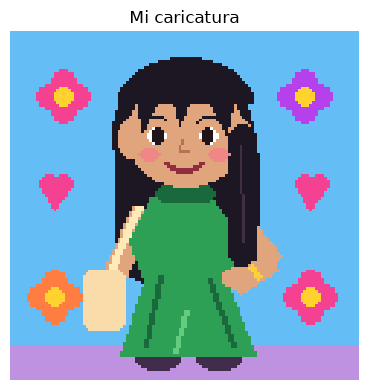

In [9]:
# Imagen de 120 × 120 píxeles con fondo celeste.
img = Image.new("RGB", (120, 120), (100, 190, 245))
draw = ImageDraw.Draw(img)

piel = (225, 165, 125)
cabello = (28, 23, 35)
verde = (45, 160, 85)
verde_oscuro = (25, 105, 60)
rosa = (245, 65, 145)
amarillo = (255, 210, 45)

# Suelo lila.
draw.rectangle((0, 108, 119, 119), fill=(190, 145, 225))

# Flores decorativas.
def flor(x, y, color):
    for dx, dy in [(-5, 0), (5, 0), (0, -5), (0, 5)]:
        draw.ellipse(
            (x + dx - 4, y + dy - 4,
             x + dx + 4, y + dy + 4),
            fill=color
        )
    draw.ellipse((x - 3, y - 3, x + 3, y + 3), fill=amarillo)

flor(18, 22, rosa)
flor(101, 22, (180, 65, 235))
flor(15, 91, (255, 125, 65))
flor(103, 91, rosa)

# Corazones.
def corazon(x, y):
    draw.ellipse((x, y, x + 6, y + 6), fill=rosa)
    draw.ellipse((x + 5, y, x + 11, y + 6), fill=rosa)
    draw.polygon(
        [(x, y + 4), (x + 11, y + 4), (x + 5, y + 12)],
        fill=rosa
    )

corazon(10, 49)
corazon(98, 49)

# Cabello detrás de la cabeza y los hombros.
draw.ellipse((35, 9, 83, 62), fill=cabello)
draw.rounded_rectangle(
    (36, 33, 85, 86),
    radius=12,
    fill=cabello
)

# Zapatos.
draw.ellipse((43, 109, 58, 116), fill=(65, 45, 75))
draw.ellipse((64, 109, 79, 116), fill=(65, 45, 75))

# Cuello.
draw.rectangle((53, 45, 67, 62), fill=piel)

# Brazos: uno extendido y otro doblado.
draw.line([(45, 62), (32, 91)], fill=piel, width=8)
draw.ellipse((28, 87, 36, 97), fill=piel)

draw.line([(76, 62), (90, 79), (77, 87)], fill=piel, width=8)

# Bolso claro, inspirado en la foto.
draw.line([(44, 60), (32, 87)], fill=(255, 235, 185), width=3)
draw.rounded_rectangle(
    (25, 82, 39, 102),
    radius=3,
    fill=(250, 220, 170)
)

# Vestido verde largo.
draw.polygon(
    [(48, 57), (69, 57), (79, 72),
     (74, 86), (84, 111), (38, 111),
     (46, 86), (41, 72)],
    fill=verde
)

# Pliegues del vestido.
draw.line([(51, 84), (46, 108)], fill=verde_oscuro, width=2)
draw.line([(68, 85), (76, 108)], fill=verde_oscuro, width=2)
draw.line([(60, 96), (56, 110)], fill=(100, 205, 125), width=2)

# Cinta verde alrededor del cuello.
draw.rounded_rectangle(
    (50, 53, 70, 58),
    radius=2,
    fill=verde_oscuro
)

# Rostro y orejas.
draw.ellipse((37, 30, 45, 43), fill=piel)
draw.ellipse((75, 30, 83, 43), fill=piel)
draw.ellipse((40, 17, 80, 53), fill=piel)

# Flequillo.
draw.pieslice((37, 9, 83, 39), 180, 360, fill=cabello)
draw.polygon([(43, 17), (54, 17), (45, 34)], fill=cabello)
draw.polygon([(54, 15), (65, 15), (58, 32)], fill=cabello)
draw.polygon([(65, 16), (77, 20), (74, 35)], fill=cabello)

# Mechón largo a un lado.
draw.rounded_rectangle(
    (75, 32, 84, 80),
    radius=4,
    fill=cabello
)
draw.line([(79, 39), (80, 72)], fill=(65, 48, 65), width=1)

# Ojos.
draw.ellipse((47, 33, 53, 38), fill="white")
draw.ellipse((65, 33, 71, 38), fill="white")
draw.ellipse((49, 33, 52, 38), fill=(30, 20, 25))
draw.ellipse((66, 33, 69, 38), fill=(30, 20, 25))

# Cejas.
draw.arc((46, 29, 54, 34), 190, 340, fill=cabello, width=1)
draw.arc((64, 29, 72, 34), 190, 340, fill=cabello, width=1)

# Nariz, mejillas y sonrisa.
draw.line([(59, 37), (58, 41), (61, 41)], fill=(180, 115, 85))
draw.ellipse((44, 40, 51, 44), fill=(240, 135, 135))
draw.ellipse((68, 40, 75, 44), fill=(240, 135, 135))
draw.arc((53, 40, 66, 48), 10, 170, fill=(145, 45, 65), width=2)

# Mano sobre la cintura y pulsera.
draw.ellipse((73, 81, 82, 88), fill=piel)
draw.line([(82, 80), (85, 84)], fill=amarillo, width=2)

img.save("mi_imagen.png")

print("Tamaño:", img.size)
print("Modo:", img.mode)

mostrar([img], ["Mi caricatura"])

In [10]:
img = Image.open("mi_imagen.png")
img.load()

p_fondo = (5, 5)
p_vestido = (60, 90)
p_flor = (18, 22)

print("Formato:", img.format)
print("Tamaño:", img.size)
print("Modo:", img.mode)

print("Fondo", p_fondo, ":", img.getpixel(p_fondo))
print("Vestido", p_vestido, ":", img.getpixel(p_vestido))
print("Centro de la flor", p_flor, ":", img.getpixel(p_flor))

Formato: PNG
Tamaño: (120, 120)
Modo: RGB
Fondo (5, 5) : (100, 190, 245)
Vestido (60, 90) : (45, 160, 85)
Centro de la flor (18, 22) : (255, 210, 45)


Escala de grises : (120, 120)
Rotación 90° : (120, 120)
Reducción : (60, 60)
Flip vertical : (120, 120)


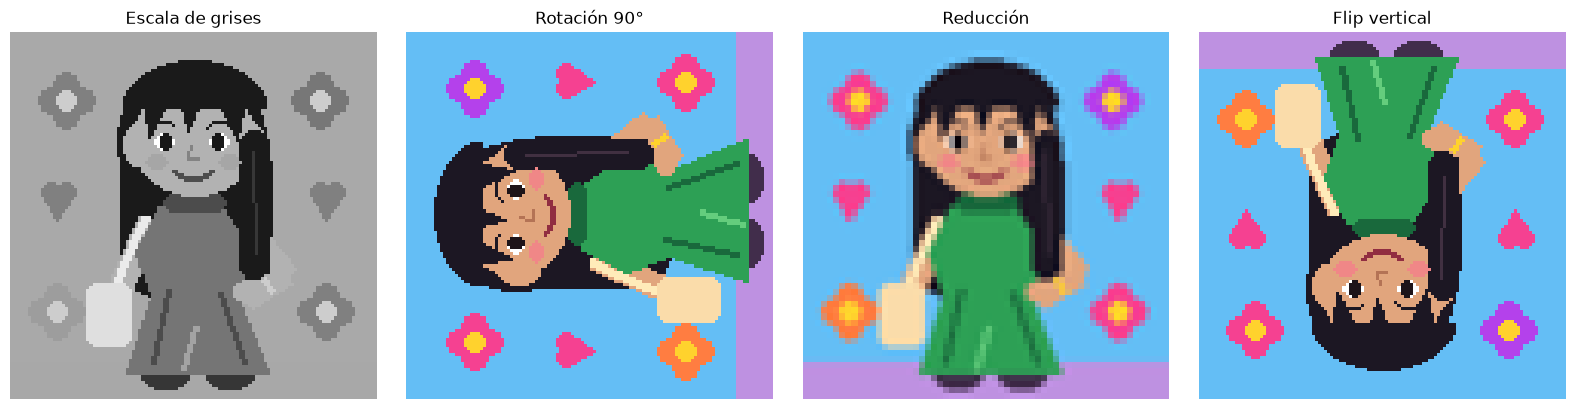

In [11]:
gris_pillow = img.convert("L")
rotada = img.rotate(90, expand=True)
reducida = img.resize((60, 60))
volteada = img.transpose(Image.Transpose.FLIP_TOP_BOTTOM)

imagenes = [gris_pillow, rotada, reducida, volteada]
titulos = ["Escala de grises", "Rotación 90°", "Reducción", "Flip vertical"]

for titulo, imagen in zip(titulos, imagenes):
    print(titulo, ":", imagen.size)

mostrar(imagenes, titulos)

Píxel analizado: (18, 22)
Antes: (255, 210, 45)
Después: (255, 255, 112)
Canal R: valor calculado = 637.5; valor final = 255; recorte = True
Canal G: valor calculado = 525.0; valor final = 255; recorte = True
Canal B: valor calculado = 112.5; valor final = 112; recorte = False


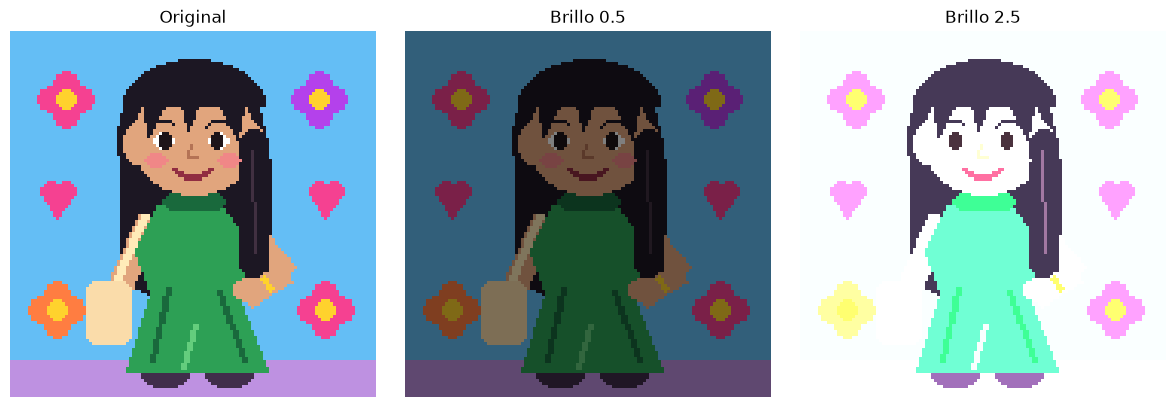

In [12]:
brillo_bajo = ImageEnhance.Brightness(img).enhance(0.5)
brillo_alto = ImageEnhance.Brightness(img).enhance(2.5)

antes = img.getpixel(p_flor)
despues = brillo_alto.getpixel(p_flor)

print("Píxel analizado:", p_flor)
print("Antes:", antes)
print("Después:", despues)

for canal, original, resultado in zip("RGB", antes, despues):
    calculado = original * 2.5
    recorte = calculado > 255 or calculado < 0

    print(
        f"Canal {canal}: valor calculado = {calculado}; "
        f"valor final = {resultado}; recorte = {recorte}"
    )

mostrar(
    [img, brillo_bajo, brillo_alto],
    ["Original", "Brillo 0.5", "Brillo 2.5"]
)

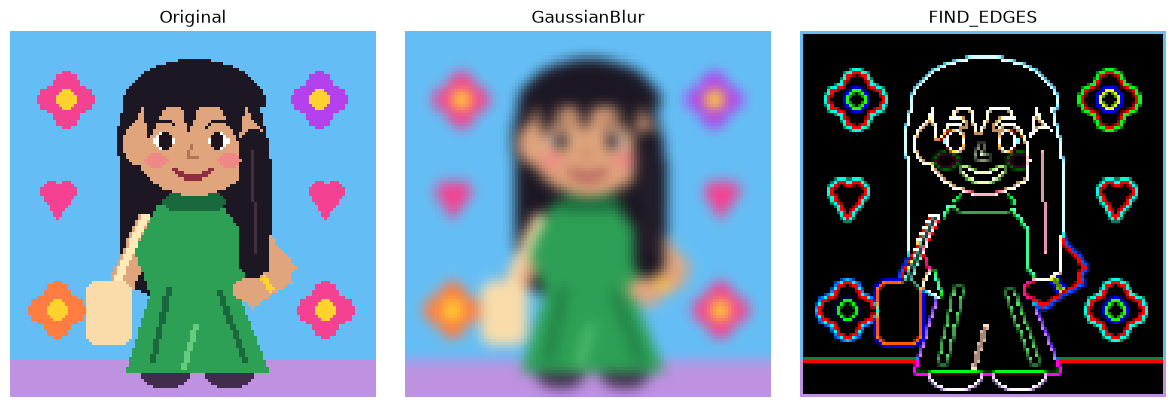

Se guardaron los dos archivos PNG.


In [13]:
blur = img.filter(ImageFilter.GaussianBlur(radius=2))
bordes = img.filter(ImageFilter.FIND_EDGES)

blur.save("mi_imagen_blur.png")
bordes.save("mi_imagen_bordes.png")

mostrar(
    [img, blur, bordes],
    ["Original", "GaussianBlur", "FIND_EDGES"]
)

print("Se guardaron los dos archivos PNG.")

Coordenadas del fondo: (5, 5)
Color original: (100, 190, 245)
Gris con Pillow: 169
Gris con scikit-image × 255: 174.8405
Diferencia: 5.8405
Tipo del array RGB: uint8
Tipo del gris de scikit-image: float64


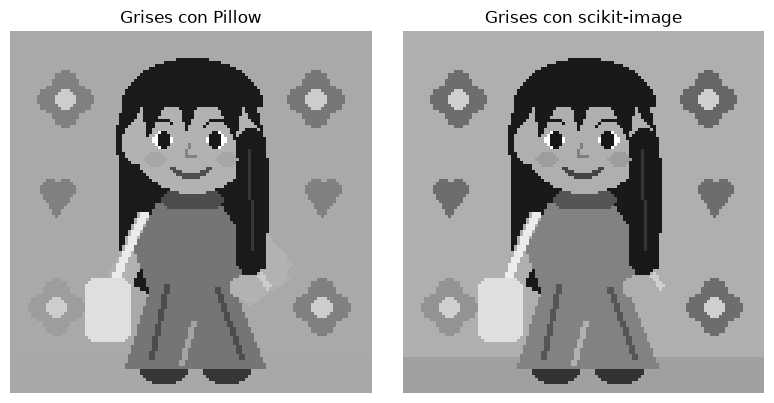

In [14]:
imagen_array = np.array(img)

gris_pillow = img.convert("L")
gris_skimage = color.rgb2gray(imagen_array)

# Pillow utiliza (x, y); NumPy utiliza [y, x].
x, y = p_fondo

valor_pillow = gris_pillow.getpixel((x, y))
valor_skimage = float(gris_skimage[y, x] * 255)

print("Coordenadas del fondo:", p_fondo)
print("Color original:", img.getpixel(p_fondo))

print("Gris con Pillow:", valor_pillow)
print("Gris con scikit-image × 255:", round(valor_skimage, 4))
print("Diferencia:", round(abs(valor_pillow - valor_skimage), 4))

print("Tipo del array RGB:", imagen_array.dtype)
print("Tipo del gris de scikit-image:", gris_skimage.dtype)

mostrar(
    [gris_pillow, gris_skimage],
    ["Grises con Pillow", "Grises con scikit-image"]
)

Umbral de Otsu: 0.332162
Proporción True: 0.874444
Porcentaje True: 87.44 %


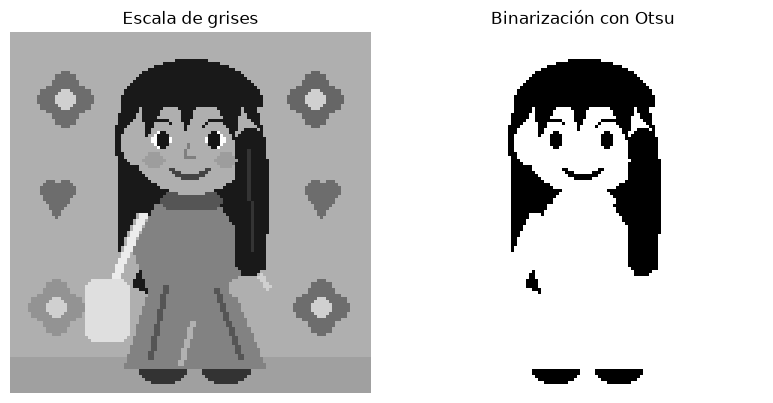

In [15]:
umbral_otsu = filters.threshold_otsu(gris_skimage)
binaria_otsu = gris_skimage > umbral_otsu

proporcion_true = float(binaria_otsu.mean())

print("Umbral de Otsu:", round(float(umbral_otsu), 6))
print("Proporción True:", round(proporcion_true, 6))
print("Porcentaje True:", round(proporcion_true * 100, 2), "%")

mostrar(
    [gris_skimage, binaria_otsu],
    ["Escala de grises", "Binarización con Otsu"]
)

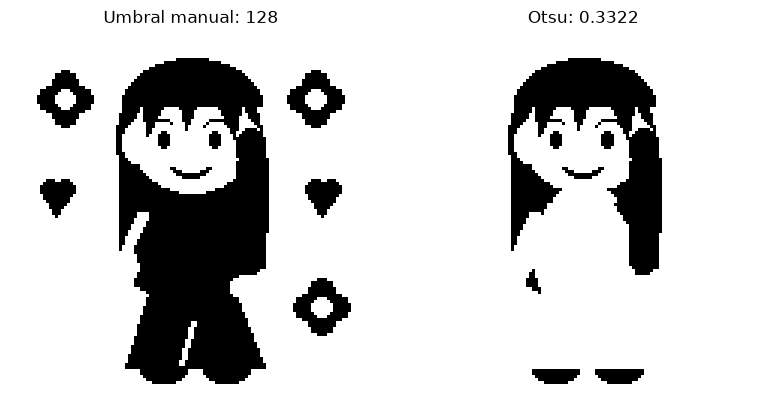

In [16]:
umbral_manual = 128

binaria_manual = gris_pillow.point(
    lambda pixel: 255 if pixel > umbral_manual else 0
)

mostrar(
    [binaria_manual, binaria_otsu],
    ["Umbral manual: 128", f"Otsu: {umbral_otsu:.4f}"]
)

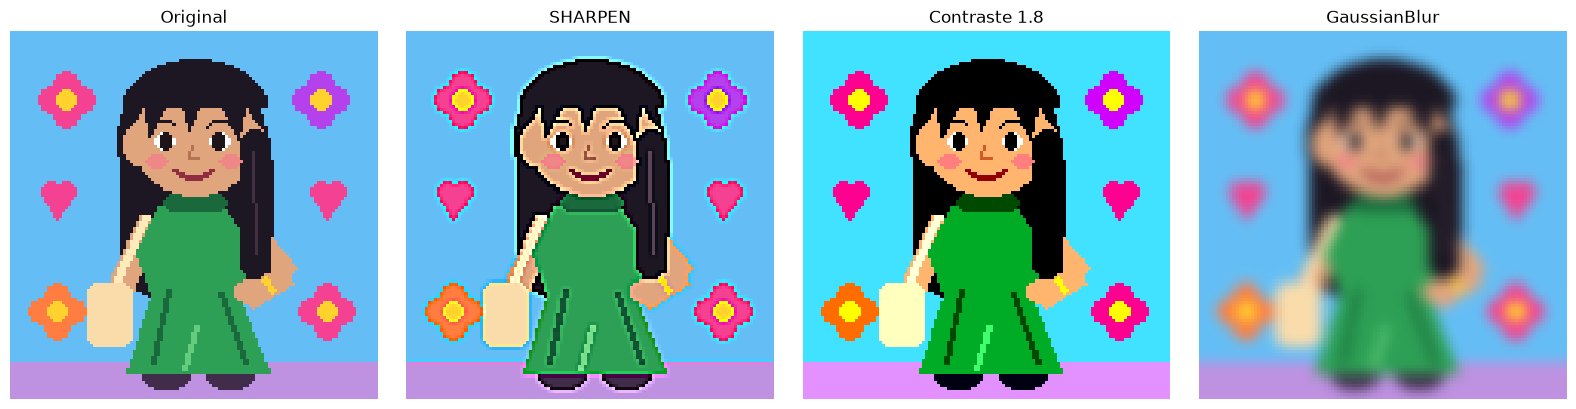

NameError: name 'resumen' is not defined

In [19]:
nitidez = img.filter(ImageFilter.SHARPEN)
contraste = ImageEnhance.Contrast(img).enhance(1.8)

mostrar(
    [img, nitidez, contraste, blur],
    ["Original", "SHARPEN", "Contraste 1.8", "GaussianBlur"]
)

texto_reto = """
## Reto opcional

SHARPEN acentúa las transiciones de los bordes, el contraste aumenta
la diferencia entre tonos y GaussianBlur suaviza los detalles.
"""

Path("procesamiento_resumen.md").write_text(
    resumen + texto_reto,
    encoding="utf-8"
)

print("Resumen actualizado.")